# **IS 4487 Assignment 9: Customer Segmentation with Clustering**

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Business Context: Hotel Bookings

### Dataset Description:

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, clustering, and trend analysis exercises.

## **Task 1. Import libraries, Load the Data and Preview it**

Business framing:  

Before we can cluster or segment anything, we need clean, accessible data in a usable format.

1.1. Import the necessary Python libraries

1.2. Load the hotel bookings dataset into a Dataframe [use this link: https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv

1.3. Display the first few rows

1.4. Show summary statistics for the Dataframe



First 5 rows of the dataset:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Summary statistics for the DataFrame:


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


### ✍️ Please answer the following:

1.4. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:

1.4. The data has a few large outliers like under lead_time the MAX is 737 days compared to the avg of 104 days. There is also Avg Daily Rate (ADR) with a MAX of $5400 compared to $101.

## **Task 2. Select and Prepare Features**

Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

2.1. Choose 3-5 numeric features related to customer behavior. Write a comment on what variables you chose

2.2. For these columns, perform any cleaning/ pre-processing steps as you see fit (drop missing values, remove outliers, remove duplicates, correct datatypes)

2.3. Standardize using `StandardScaler`

2.4. `.describe()`  the standardized columns after converting the output of StandardScaler to a Dataframe first to ensure that mean = 0 and std.dev = 1



Summary statistics of standardized behavioral features:


,lead_time,stays_in_week_nights,adr,total_of_special_requests
count,6.944300e+04,6.944300e+04,6.944300e+04,6.944300e+04
mean,-1.964549e-17,7.858198e-17,6.548498e-18,-6.548498e-17
std,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00
min,-1.041201e+00,-1.363986e+00,-2.192359e+00,-9.036126e-01
25%,-8.138427e-01,-8.899346e-01,-6.968958e-01,-9.036126e-01
50%,-3.112621e-01,5.816847e-02,-1.631211e-01,2.674816e-01
75%,5.622709e-01,5.322200e-01,5.219675e-01,2.674816e-01
max,4.894037e+00,2.233859e+01,7.708891e+00,4.951859e+00


### ✍️ Please answer the following:

2.5. What features did you select and why?

2.6. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response:
2.5. The features I choose were 1: lead time 2: stays in week night 3: Average daily rate 4: Total special requests.

2.6. The patterns I expect to find are positive relationship between ADR and stays during the week (M-F), also trends around lead time to ADR, and high ADR = high end guests = special requests.



## **Task 3. Apply K-Means Clustering**

Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

3.1. Fit a `KMeans` model with your selected features. Choose a value of `k` (e.g. 3, 4, or 5)

3.2. Predict clusters and assign a cluster number to each guest

3.3. Add the predicted values back to the scaled Dataframe. Write code to view the counts of observations in each cluster, sorted in a meaningful way.

3.4. Visualize using a scatterplot of 2 key features to show the different clusters (colors) that were identified (optionally use a third feature for size or a fourth feature for style)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.



Count of observations per cluster (sorted by size):
kmeans_cluster
1    31294
3    14711
0    12374
2    11064
Name: count, dtype: int64


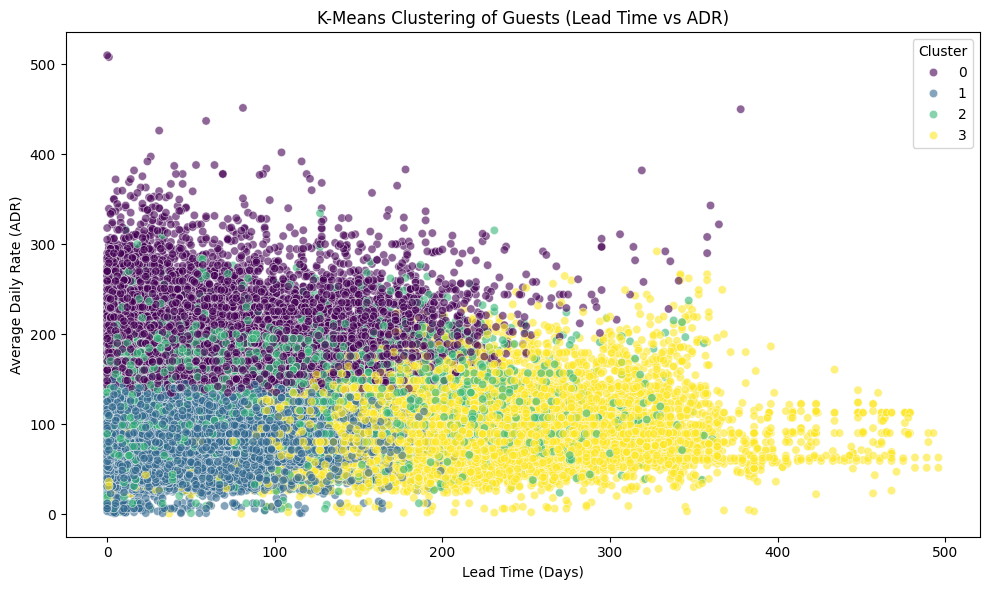

3.5. What k value did you choose, and how did you decide? I chose K =4 because it has a balance between the campaigns.
3.6. What types of customers seem to show up in the clusters?
Cluster 0 = last minute high end guests.
Cluster 1 = Last minute low budget guests
Cluster 2 = Moderate lead time and mid ADR
Cluster 3 = Long lead time and low ADR

## **Task 4. Apply Gaussian Mixture Model (GMM)**

Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

4.1. Fit a GMM with the same number of clusters you chose in Part 3

4.2. Obtain the predicted GMM cluster for each observation (assigned to cluster with the max probabilty automatically). Write code to view the counts of observations in each cluster, sorted in a meaningful way

4.3. Predict soft clusters (remember that soft clustering deals with probabilities, not labels). Show the cluster probabilities for 5 sample observations/customer records.

4.4. Visualize the GMM model so that you may compare it to the KMeans scatterplot using the same/similar chart as you created for Kmeans above

4.5. Write code to cross-tabulate the KMeans and GMM cluster predictions. This will show you where their predictions are consistent (or vary).

Ensure that all outputs 4.2-4.5 are showing below. Use print() if needed or separate the code into separate cells.


GMM Cluster Counts (sorted by size):
gmm_cluster
3    31718
2    24408
1    10601
0     2716
Name: count, dtype: int64

Sample of 5 soft clustering probabilities (representing probability of belonging to each of the 4 clusters):
[[2.38136377e-12 0.00000000e+00 0.00000000e+00 1.00000000e+00]
 [2.23356116e-12 0.00000000e+00 0.00000000e+00 1.00000000e+00]
 [3.48447086e-08 0.00000000e+00 9.99999965e-01 0.00000000e+00]
 [7.41688489e-12 0.00000000e+00 0.00000000e+00 1.00000000e+00]
 [3.59199139e-08 0.00000000e+00 9.99999964e-01 0.00000000e+00]]


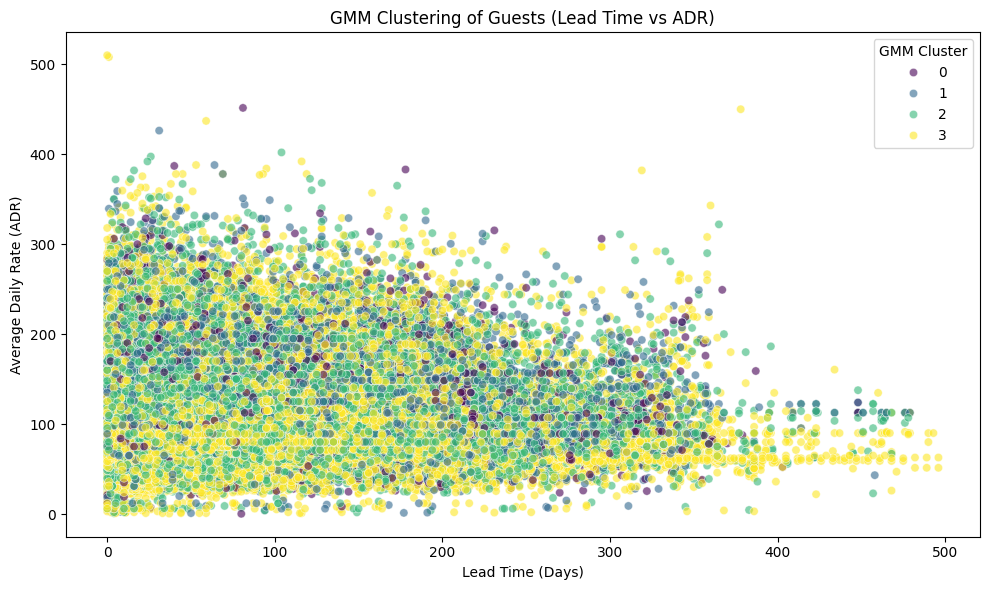


Cross-tabulation between K-Means and GMM Clusters:


gmm_cluster,0,1,2,3
kmeans_cluster,,,,
0,30,815,5682,5847
1,0,0,13053,18241
2,2395,8669,0,0
3,291,1117,5673,7630


### ✍️ Please answer the following:

4.6. How did the GMM results compare to KMeans? You can compare visualizations or cross-tabulations/contingency tables.


### ✍️ Your Response:
4.6. The KMean chart had clusters relatively grouped togther in the same area and GMM displays something different. Each cluster is spread out around the entire range of data (no real cluster in 0,1,2,3)


## **Task 5. Evaluate Your Models**

Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics, such as
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

5.1. - 5.2. Compare above metrics for both models - K-Means and GMM clusters

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering


✍️ Please answer the following:
5.3. Which model performed better on the metrics?

5.4. Would you recommend KMeans or GMM for a business analyst? Why?

✍️ Your Response:
5.3: The model that preformed the best was the KMean
5.4: I would recommed using the KMEAN, it offers better results, more reliable, and can choose a value.

## **Task 6. Business Interpretation**

Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers? For this part, choose whichever cluster model gave the best output for you.

6.1. Obtain summary statistics for relevant characteristics/variables of each cluster (e.g. average `lead_time`, `special_requests` even if they were not chosen to create clusters) to help you compare the clusters meaningfully.
  - TIP: if you obtains means of unstandardized variables, they will be easier to interpret, but standardized variables are fine too.
  - TIP: Think from a marketing or hotel operations perspective.



--- Summary Profiles (Means) of K-Means Clusters ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests,guest_count
kmeans_cluster,,,,,
0,62.144820,2.742444,189.910646,0.598028,12374
1,47.684061,2.175497,88.418949,0.417109,31294
2,74.834960,2.543113,117.216047,2.248012,11064
3,200.746312,4.734960,98.030247,0.561281,14711


### ✍️ Please answer the following:

6.2. What do the segments represent in terms of guest behavior?

6.3. How could the hotel tailor services or promotions to each group?


### ✍️ Your Response:
6.2. the largest representation of guest behavior is cluster 1. This group is the short lead time with low budget guests. The second highest is cluster 3 which is long lead times with low ADR

6.3. The hotel can tailor deal around the 45-50 day lead time and offer discounts to capture more guests that fall into the category. They can also provide an extra discount for longer stays during the week as well.


## **Task 7. Final Reflection**

Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### ✍️ Please answer the following:

7.1. What was most challenging about unsupervised learning?

7.2. When would you use clustering instead of supervised models?

7.3. How would you explain the value of clustering to a non-technical manager?

7.4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response:

7.1. The most challenging part about unsupervised learning can be if you get lost or don't know which route to take and you take the wrong one, you will end up very wrong. With supervised learning you can ask for help and guidence on which steps to take.

7.2. I would use clustering when i don't know what trend or patterns are in the data or what answer the data contains.

7.3. Through clustering we can identify different types of customers like last minute low budget or long lead times guests. We can see the difference between when they book, prices, and what days they typically stay.

7.4. This related to the canvas outcome by bridging the gap between raw data and structure business operations.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas


In [9]:
!jupyter nbconvert --to html "assignment_09_ShermanEthan.ipynb"

[NbConvertApp] Converting notebook assignment_09_ShermanEthan.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 1610750 bytes to assignment_09_ShermanEthan.html
